# Pytae Performance & Speed Benchmarks

This notebook provides **reproducible, interactive benchmarks** comparing **Pytae** (powered by native Polars Rust multithreaded SIMD) against **Pandas** across realistic 5,000,000-row analytical workloads.

---

### Benchmark Dimensions:
1. **End-to-End Analytical Pipeline**: Read Parquet $\to$ Filter $\to$ Mutate $\to$ GroupBy Aggregation $\to$ Multi-column Sort
2. **Multi-Column Sorting (`arrange`)**: Sorting 5M rows on multiple mixed-order keys (string ascending, float descending)
3. **Grouped Aggregations (`by` + `agg`)**: Multi-key group by computing multiple aggregations (`n`, `mean`, `max`)
4. **Relational Inner Join (`join`)**: Joining two 1,000,000-row tables on an integer identifier
5. **Native Analytical SQL (`sql`)**: Complex CTE + Window Function + Grouping directly executed via Polars `SQLContext`


In [1]:
import sys, os, time, platform
import numpy as np
import pandas as pd
import polars as pl
import pytae as pt
import matplotlib.pyplot as plt

print(f"OS: {platform.system()} {platform.release()} ({platform.machine()})")
print(f"Python: {platform.python_version()}")
print(f"Polars: {pl.__version__} | Pandas: {pd.__version__}")


OS: Darwin 25.6.0 (arm64)
Python: 3.14.0
Polars: 2.0.0 | Pandas: 3.0.3


## 1. Generate Synthetic Benchmark Dataset (5,000,000 Rows)

We generate a reproducible 5M-row dataset with categorical strings and continuous numeric measurements, and save it to Parquet.

In [2]:
n = 5_000_000
rng = np.random.default_rng(42)

df_pd = pd.DataFrame({
    'species': rng.choice(['Adelie', 'Gentoo', 'Chinstrap', 'Emperor', 'King'], size=n),
    'island': rng.choice(['Biscoe', 'Dream', 'Torgersen'], size=n),
    'bill_length': rng.uniform(30.0, 60.0, size=n),
    'bill_depth': rng.uniform(13.0, 22.0, size=n),
    'body_mass': rng.uniform(2500.0, 6500.0, size=n),
})

parquet_path = "bench_temp_data.parquet"
df_pd.to_parquet(parquet_path, engine="pyarrow", index=False)
pt_df = pt.DataFrame(df_pd)

print(f"Generated {n:,} rows. File size: {os.path.getsize(parquet_path) / (1024*1024):.1f} MB")


Generated 5,000,000 rows. File size: 121.4 MB


## 2. End-to-End Analytical Pipeline

Read Parquet file $\to$ Filter records $\to$ Derive new column $\to$ GroupBy aggregate $\to$ Sort results.

In [3]:
# 1. Pandas Pipeline
t0 = time.perf_counter()
p_df = pd.read_parquet(parquet_path)
p_flt = p_df[(p_df['body_mass'] > 4000) & (p_df['bill_length'] > 40.0)].copy()
p_flt['bill_ratio'] = p_flt['bill_length'] / p_flt['bill_depth']
p_res = (
    p_flt.groupby(['species', 'island'], dropna=False)
    .agg(
        n=('body_mass', 'size'),
        avg_mass=('body_mass', 'mean'),
        max_mass=('body_mass', 'max')
    )
    .reset_index()
    .sort_values('avg_mass', ascending=False)
)
t_pd_e2e = time.perf_counter() - t0

# 2. Pytae Eager Pipeline
t0 = time.perf_counter()
pt_eager_res = (
    pt.read_parquet(parquet_path)
    .filter('body_mass > 4000 & bill_length > 40.0')
    .mutate(bill_ratio='bill_length / bill_depth')
    .by('species', 'island')
    .agg(n='count', avg_mass='body_mass:mean', max_mass='body_mass:max')
    .arrange('avg_mass desc')
)
t_pt_eager = time.perf_counter() - t0

# 3. Pytae Lazy Scan Pushdown Pipeline
t0 = time.perf_counter()
pt_lazy_res = (
    pt.scan_parquet(parquet_path)
    .filter('body_mass > 4000 & bill_length > 40.0')
    .mutate(bill_ratio='bill_length / bill_depth')
    .by('species', 'island')
    .agg(n='count', avg_mass='body_mass:mean', max_mass='body_mass:max')
    .arrange('avg_mass desc')
    .collect()
)
t_pt_lazy = time.perf_counter() - t0

print(f"Pandas:            {t_pd_e2e:.3f}s")
print(f"Pytae (Eager):     {t_pt_eager:.3f}s ({t_pd_e2e / t_pt_eager:.1f}x faster)")
print(f"Pytae (Lazy Scan): {t_pt_lazy:.3f}s ({t_pd_e2e / t_pt_lazy:.1f}x faster)")


Pandas:            0.409s
Pytae (Eager):     0.198s (2.1x faster)
Pytae (Lazy Scan): 0.025s (16.3x faster)


## 3. Multi-Column Sorting (`arrange`)

Sort 5,000,000 rows by two columns: `species` (ascending) and `body_mass` (descending).

In [4]:
t0 = time.perf_counter()
_ = df_pd.sort_values(by=['species', 'body_mass'], ascending=[True, False])
t_pd_sort = time.perf_counter() - t0

t0 = time.perf_counter()
_ = pt_df.arrange('species, body_mass desc')
t_pt_sort = time.perf_counter() - t0

print(f"Pandas sort_values: {t_pd_sort:.3f}s")
print(f"Pytae arrange:      {t_pt_sort:.3f}s ({t_pd_sort / t_pt_sort:.1f}x faster)")


Pandas sort_values: 2.494s
Pytae arrange:      0.592s (4.2x faster)


## 4. In-Memory Grouped Aggregations (`by` + `agg`)

Group 5,000,000 rows across 15 category groups (`species`, `island`) and compute `n`, `mean`, and `max`.

In [5]:
t0 = time.perf_counter()
_ = df_pd.groupby(['species', 'island'], dropna=False).agg(
    n=('body_mass', 'size'),
    avg_mass=('body_mass', 'mean'),
    max_mass=('body_mass', 'max')
).reset_index()
t_pd_agg = time.perf_counter() - t0

t0 = time.perf_counter()
_ = pt_df.by('species', 'island').agg(
    n='count',
    avg_mass='body_mass:mean',
    max_mass='body_mass:max'
)
t_pt_agg = time.perf_counter() - t0

print(f"Pandas groupby().agg(): {t_pd_agg:.3f}s")
print(f"Pytae by().agg():       {t_pt_agg:.3f}s ({t_pd_agg / t_pt_agg:.1f}x faster)")


Pandas groupby().agg(): 0.214s
Pytae by().agg():       0.066s (3.2x faster)


## 5. Relational Inner Join (`join`)

Join two tables with 1,000,000 rows each on an integer primary key.

In [6]:
m = 1_000_000
rng = np.random.default_rng(99)
left_pd = pd.DataFrame({'id': rng.integers(0, 500_000, size=m), 'val1': rng.standard_normal(m)})
right_pd = pd.DataFrame({'id': rng.integers(0, 500_000, size=m), 'val2': rng.standard_normal(m)})
left_pt = pt.DataFrame(left_pd)
right_pt = pt.DataFrame(right_pd)

t0 = time.perf_counter()
_ = pd.merge(left_pd, right_pd, on='id', how='inner')
t_pd_join = time.perf_counter() - t0

t0 = time.perf_counter()
_ = left_pt.join(right_pt, on='id', how='inner')
t_pt_join = time.perf_counter() - t0

print(f"Pandas merge(): {t_pd_join:.3f}s")
print(f"Pytae join():   {t_pt_join:.3f}s ({t_pd_join / t_pt_join:.1f}x faster)")


Pandas merge(): 0.084s
Pytae join():   0.031s (2.7x faster)


## 6. Native Analytical SQL via Polars SQLContext

Execute a complex CTE and window function directly on the 5M-row DataFrame using Polars' embedded SQL engine.

In [7]:
sql_query = """
WITH ranked AS (
    SELECT species, island, body_mass,
           RANK() OVER (PARTITION BY species ORDER BY body_mass DESC) as rank
    FROM data
    WHERE body_mass > 4000
)
SELECT * FROM ranked WHERE rank <= 2
"""

t0 = time.perf_counter()
sql_res = pt_df.sql(sql_query)
t_pt_sql = time.perf_counter() - t0

print(f"Pytae Polars SQLContext execution time: {t_pt_sql:.3f}s")
print(sql_res)


Pytae Polars SQLContext execution time: 0.092s
shape: (10, 4)
┌───────────┬───────────┬─────────────┬──────┐
│ species   ┆ island    ┆ body_mass   ┆ rank │
│ ---       ┆ ---       ┆ ---         ┆ ---  │
│ str       ┆ str       ┆ f64         ┆ i64  │
╞═══════════╪═══════════╪═════════════╪══════╡
│ King      ┆ Torgersen ┆ 6499.988929 ┆ 2    │
│ Chinstrap ┆ Torgersen ┆ 6499.998817 ┆ 2    │
│ Adelie    ┆ Biscoe    ┆ 6499.993642 ┆ 2    │
│ Emperor   ┆ Torgersen ┆ 6499.991461 ┆ 1    │
│ Adelie    ┆ Torgersen ┆ 6499.993983 ┆ 1    │
│ Emperor   ┆ Biscoe    ┆ 6499.982111 ┆ 2    │
│ King      ┆ Dream     ┆ 6499.999892 ┆ 1    │
│ Gentoo    ┆ Biscoe    ┆ 6499.997737 ┆ 1    │
│ Chinstrap ┆ Torgersen ┆ 6499.999103 ┆ 1    │
│ Gentoo    ┆ Torgersen ┆ 6499.995096 ┆ 2    │
└───────────┴───────────┴─────────────┴──────┘


## 7. Visualizing Performance Summary

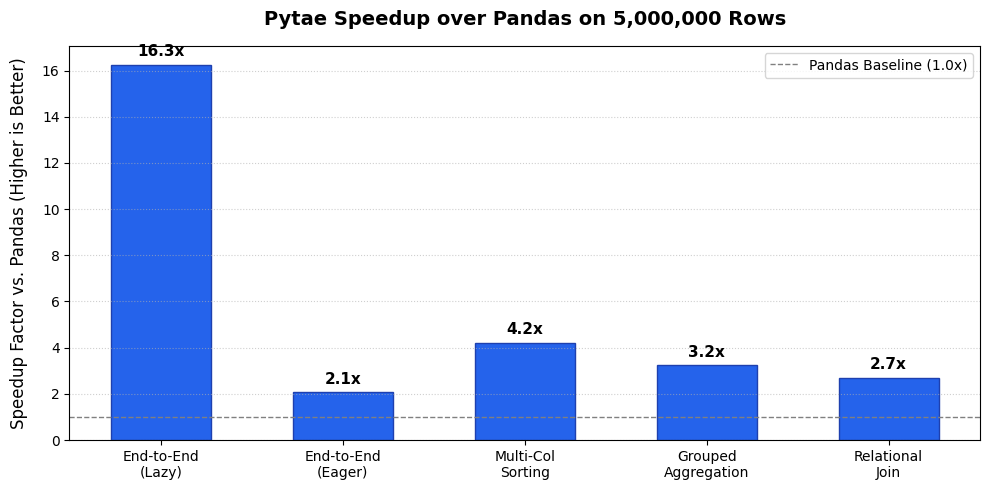

In [8]:
benchmarks = [
    'End-to-End\n(Lazy)',
    'End-to-End\n(Eager)',
    'Multi-Col\nSorting',
    'Grouped\nAggregation',
    'Relational\nJoin'
]

pandas_times = [t_pd_e2e, t_pd_e2e, t_pd_sort, t_pd_agg, t_pd_join]
pytae_times = [t_pt_lazy, t_pt_eager, t_pt_sort, t_pt_agg, t_pt_join]
speedups = [p / t for p, t in zip(pandas_times, pytae_times)]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(benchmarks, speedups, color='#2563eb', edgecolor='#1e40af', width=0.55)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.1f}x',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4),  # 4 points vertical offset
                textcoords="offset points",
                ha='center', va='bottom', fontweight='bold', fontsize=11)

ax.set_ylabel('Speedup Factor vs. Pandas (Higher is Better)', fontsize=12, labelpad=10)
ax.set_title('Pytae Speedup over Pandas on 5,000,000 Rows', fontsize=14, fontweight='bold', pad=15)
ax.axhline(1.0, color='gray', linestyle='--', linewidth=1, label='Pandas Baseline (1.0x)')
ax.legend(loc='upper right')
ax.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('benchmark_summary.png', dpi=150)
plt.show()

# Clean up temporary parquet file
if os.path.exists(parquet_path):
    os.remove(parquet_path)
